## Model 4: Fine-Tuned BERT with WordNet-Enhanced Features

For the final model, we used a **fine-tuned BERT classifier enhanced with WordNet-based lexical-semantic features**. This model was designed to combine the strong contextual representation ability of transformer models with additional linguistic information derived from WordNet.

Unlike a standard BERT classifier that relies only on contextual embeddings, our method augments the text representation with four handcrafted semantic features. These additional features aim to capture differences in lexical coverage and semantic structure between **human-written** and **AI-generated** text.

In this final submission notebook, the full model pipeline is summarised in a single file, including:

- the task setting and data split description
- the WordNet feature engineering process
- the BERT + WordNet fusion architecture
- the training and evaluation pipeline
- the final saved validation and test results

To keep the notebook lightweight and submission-ready, the executed cells below load the **saved formal comparison artifacts only**. No retraining or expensive full inference is performed here.

### Input and Label Setting

Our dataset uses the following label definitions:

- **0 = human-written text**
- **1 = AI-generated text**

The final formal comparison version of this model uses:

- **50,000** training examples
- **10,000** validation examples
- **211,185** test examples from the full official test set

The notebook below first loads the saved run artifacts, then presents the main code components of the model, and finally reports the confirmed evaluation results with figures.

In [1]:
from __future__ import annotations

import json
import random
import re
from dataclasses import dataclass
from functools import lru_cache
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from nltk import pos_tag
from nltk.corpus import wordnet as wn
from nltk.stem import WordNetLemmatizer
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, Dataset
from transformers import AutoModel

pd.set_option('display.max_colwidth', 120)
pd.set_option('display.precision', 4)
plt.rcParams['figure.dpi'] = 130
print('Libraries imported successfully.')

Libraries imported successfully.


In [2]:
CWD = Path.cwd()

PROJECT_DIR_CANDIDATES = [CWD, CWD / 'project']
PROJECT_DIR = next((path for path in PROJECT_DIR_CANDIDATES if (path / 'outputs').exists() and (path / 'model4.ipynb').exists()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError('Could not locate the project notebook directory from the current working directory.')

DATA_ROOT_CANDIDATES = [
    PROJECT_DIR.parent / 'comp6713-ass2',
    CWD / 'comp6713-ass2',
    CWD.parent / 'comp6713-ass2',
]
DATA_ROOT = next((path for path in DATA_ROOT_CANDIDATES if path.exists()), None)
if DATA_ROOT is None:
    raise FileNotFoundError('Could not locate the comp6713-ass2 project directory from the current working directory.')

RUN_DIR = PROJECT_DIR / 'outputs' / 'team_split_bert_wordnet' / 'team_split_compare_large'
TEAM_SPLIT_ROOT = DATA_ROOT / 'datasets' / 'splits'

METRICS_PATH = RUN_DIR / 'metrics.json'
RUN_INFO_PATH = RUN_DIR / 'run_info.json'
MODEL_CONFIG_PATH = RUN_DIR / 'model_config.json'
EPOCH_METRICS_PATH = RUN_DIR / 'epoch_metrics.json'
VAL_PREDICTIONS_PATH = RUN_DIR / 'val_predictions.csv'
TEST_PREDICTIONS_PATH = RUN_DIR / 'test_predictions.csv'
TRAIN_PATH = TEAM_SPLIT_ROOT / 'train.parquet'
VAL_PATH = TEAM_SPLIT_ROOT / 'val.parquet'
TEST_PATH = TEAM_SPLIT_ROOT / 'test.parquet'

required_paths = [
    METRICS_PATH,
    RUN_INFO_PATH,
    MODEL_CONFIG_PATH,
    EPOCH_METRICS_PATH,
    VAL_PREDICTIONS_PATH,
    TEST_PREDICTIONS_PATH,
    TRAIN_PATH,
    VAL_PATH,
    TEST_PATH,
]
missing_paths = [str(path) for path in required_paths if not path.exists()]
if missing_paths:
    raise FileNotFoundError('Missing required files:\n' + '\n'.join(missing_paths))

metrics = json.loads(METRICS_PATH.read_text(encoding='utf-8'))
run_info = json.loads(RUN_INFO_PATH.read_text(encoding='utf-8'))
model_config = json.loads(MODEL_CONFIG_PATH.read_text(encoding='utf-8'))
epoch_metrics = json.loads(EPOCH_METRICS_PATH.read_text(encoding='utf-8'))

val_predictions = pd.read_csv(VAL_PREDICTIONS_PATH)
test_predictions = pd.read_csv(TEST_PREDICTIONS_PATH)
train_labels = pd.read_parquet(TRAIN_PATH, columns=['label'])
val_labels_full = pd.read_parquet(VAL_PATH, columns=['label'])
test_labels_full = pd.read_parquet(TEST_PATH, columns=['label'])

print('Loaded saved final-run artifacts from:')
print(RUN_DIR.relative_to(PROJECT_DIR).as_posix())
print()
print('Validation prediction rows:', len(val_predictions))
print('Test prediction rows:', len(test_predictions))

Loaded saved final-run artifacts from:
outputs/team_split_bert_wordnet/team_split_compare_large

Validation prediction rows: 10000
Test prediction rows: 211185


### Data Split Description

The project uses the official train, validation, and test splits produced during preprocessing. These splits are treated as the shared source of truth for all later experiments.

For the final formal comparison run of Model 4, a subset of the training and validation data was used for practical fine-tuning, while the **full official test set** was retained for final evaluation. This setting allows the final reported result to reflect large-scale testing performance while keeping training computationally manageable.

In [3]:
official_split_summary = pd.DataFrame(
    [
        {'split': 'train', 'rows': len(train_labels), 'human_0': int((train_labels['label'] == 0).sum()), 'ai_1': int((train_labels['label'] == 1).sum())},
        {'split': 'validation', 'rows': len(val_labels_full), 'human_0': int((val_labels_full['label'] == 0).sum()), 'ai_1': int((val_labels_full['label'] == 1).sum())},
        {'split': 'test', 'rows': len(test_labels_full), 'human_0': int((test_labels_full['label'] == 0).sum()), 'ai_1': int((test_labels_full['label'] == 1).sum())},
    ]
)

final_setting_summary = pd.DataFrame(
    [
        {'item': 'run_name', 'value': run_info['run_name']},
        {'item': 'train_size', 'value': run_info['sample_sizes']['train']},
        {'item': 'validation_size', 'value': run_info['sample_sizes']['val']},
        {'item': 'test_size', 'value': len(test_predictions)},
        {'item': 'device', 'value': run_info['device']},
        {'item': 'batch_size', 'value': run_info['config']['batch_size']},
        {'item': 'max_length', 'value': run_info['config']['max_length']},
        {'item': 'epochs', 'value': run_info['config']['epochs']},
        {'item': 'learning_rate', 'value': f"{run_info['config']['learning_rate']:.0e}"},
        {'item': 'weight_decay', 'value': run_info['config']['weight_decay']},
    ]
)

print('Official split summary')
print(official_split_summary.to_string(index=False))
print()
print('Final saved run configuration')
print(final_setting_summary.to_string(index=False))

Official split summary
     split   rows  human_0   ai_1
     train 985525   724975 260550
validation 211184   155352  55832
      test 211185   155352  55833

Final saved run configuration
           item                    value
       run_name team_split_compare_large
     train_size                    50000
validation_size                    10000
      test_size                   211185
         device                     cuda
     batch_size                        8
     max_length                      256
         epochs                        1
  learning_rate                    2e-05
   weight_decay                     0.01


### WordNet Feature Engineering

In addition to the BERT text representation, this model introduces four WordNet-derived features:

- **average synset count**
- **average synonym count**
- **WordNet coverage ratio**
- **average hypernym depth**

These features are extracted from content words after tokenization, part-of-speech tagging, and lemmatization. The purpose is to provide extra lexical-semantic signals that may help distinguish human and AI writing styles beyond contextual embeddings alone.

In [4]:
FEATURE_COLUMNS = [
    'wn_avg_synset_count',
    'wn_avg_synonym_count',
    'wn_coverage_ratio',
    'wn_avg_hypernym_depth',
]

TOKEN_PATTERN = re.compile(r"[A-Za-z]+(?:'[A-Za-z]+)?")
LEMMATIZER = WordNetLemmatizer()
CONTENT_TAG_PREFIXES = ('NN', 'VB', 'JJ', 'RB')


def tokenize_text(text: str) -> list[str]:
    return TOKEN_PATTERN.findall(text.lower())


def is_content_pos(tag: str) -> bool:
    return tag.startswith(CONTENT_TAG_PREFIXES)


def penn_to_wordnet_pos(tag: str) -> str | None:
    if tag.startswith('NN'):
        return wn.NOUN
    if tag.startswith('VB'):
        return wn.VERB
    if tag.startswith('JJ'):
        return wn.ADJ
    if tag.startswith('RB'):
        return wn.ADV
    return None


@lru_cache(maxsize=50000)
def get_wordnet_stats(lemma: str, wn_pos: str) -> tuple[int, int, int]:
    synsets = wn.synsets(lemma, pos=wn_pos)
    synset_count = len(synsets)
    if not synsets:
        return 0, 0, 0
    synonym_count = len({item.name() for synset in synsets for item in synset.lemmas()})
    hypernym_depth = synsets[0].max_depth()
    return synset_count, synonym_count, hypernym_depth


def extract_content_words(text: str) -> list[tuple[str, str]]:
    tokens = tokenize_text(text)
    if not tokens:
        return []
    tagged_tokens = pos_tag(tokens)
    content_words = []
    for token, tag in tagged_tokens:
        if not is_content_pos(tag):
            continue
        wn_pos = penn_to_wordnet_pos(tag)
        if wn_pos is None:
            continue
        lemma = LEMMATIZER.lemmatize(token, pos=wn_pos)
        if lemma:
            content_words.append((lemma, wn_pos))
    return content_words


def compute_wordnet_features(text: str) -> dict[str, float]:
    content_words = extract_content_words(text)
    total_content_words = len(content_words)
    if total_content_words == 0:
        return {column: 0.0 for column in FEATURE_COLUMNS}

    synset_counts = []
    synonym_counts = []
    hypernym_depths = []
    covered_count = 0

    for lemma, wn_pos in content_words:
        synset_count, synonym_count, hypernym_depth = get_wordnet_stats(lemma, wn_pos)
        synset_counts.append(synset_count)
        synonym_counts.append(synonym_count)
        if synset_count > 0:
            covered_count += 1
            hypernym_depths.append(hypernym_depth)

    return {
        'wn_avg_synset_count': sum(synset_counts) / total_content_words,
        'wn_avg_synonym_count': sum(synonym_counts) / total_content_words,
        'wn_coverage_ratio': covered_count / total_content_words,
        'wn_avg_hypernym_depth': sum(hypernym_depths) / len(hypernym_depths) if hypernym_depths else 0.0,
    }


def add_wordnet_features(df: pd.DataFrame, text_column: str = 'text') -> pd.DataFrame:
    feature_df = df[text_column].fillna('').astype(str).apply(compute_wordnet_features).apply(pd.Series)
    return pd.concat([df.copy(), feature_df], axis=1)

print('Defined WordNet feature engineering functions.')
print('Feature columns:', FEATURE_COLUMNS)

Defined WordNet feature engineering functions.
Feature columns: ['wn_avg_synset_count', 'wn_avg_synonym_count', 'wn_coverage_ratio', 'wn_avg_hypernym_depth']


### BERT + WordNet Fusion Model

The classifier uses a **BERT encoder** to obtain a contextual representation of the input text. This pooled text representation is then concatenated with the four normalized WordNet features.

The combined vector is passed through a small feed-forward classifier for binary prediction. In this way, the model jointly uses:

- transformer-based contextual information from BERT
- lexical-semantic information from WordNet features

The code below shows the core configuration class, model class, and dataset wrapper used in the project.

In [5]:
@dataclass
class BertWordNetConfig:
    model_name: str = 'bert-base-uncased'
    wordnet_feature_dim: int = 4
    dropout: float = 0.1
    num_labels: int = 2


class BertWordNetClassifier(nn.Module):
    def __init__(self, config: BertWordNetConfig) -> None:
        super().__init__()
        self.config = config
        self.bert = AutoModel.from_pretrained(config.model_name)
        hidden_size = self.bert.config.hidden_size

        self.dropout = nn.Dropout(config.dropout)
        self.classifier = nn.Sequential(
            nn.Linear(hidden_size + config.wordnet_feature_dim, hidden_size // 2),
            nn.ReLU(),
            nn.Dropout(config.dropout),
            nn.Linear(hidden_size // 2, config.num_labels),
        )

    def forward(self, input_ids, attention_mask, wordnet_features, labels=None):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        pooled_output = outputs.last_hidden_state[:, 0]
        fused_input = torch.cat([self.dropout(pooled_output), wordnet_features], dim=1)
        logits = self.classifier(fused_input)

        result = {'logits': logits}
        if labels is not None:
            result['loss'] = nn.CrossEntropyLoss()(logits, labels)
        return result


class BertWordNetDataset(Dataset):
    def __init__(self, df: pd.DataFrame, tokenizer, scaler: StandardScaler, max_length: int) -> None:
        self.df = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_length = max_length
        self.features = scaler.transform(self.df[FEATURE_COLUMNS].to_numpy())

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int):
        row = self.df.iloc[idx]
        encoding = self.tokenizer(
            row['text'],
            truncation=True,
            padding='max_length',
            max_length=self.max_length,
            return_tensors='pt',
        )
        return {
            'example_id': row['example_id'],
            'input_ids': encoding['input_ids'].squeeze(0),
            'attention_mask': encoding['attention_mask'].squeeze(0),
            'wordnet_features': torch.tensor(self.features[idx], dtype=torch.float32),
            'labels': torch.tensor(int(row['label']), dtype=torch.long),
        }

print('Defined BERT + WordNet model classes.')

Defined BERT + WordNet model classes.


### Training and Evaluation Pipeline

The project training pipeline includes seed control, feature normalization, mini-batch data loading, metric computation, and evaluation on validation or test data.

For this final submission notebook, the code is included to document the full modelling workflow, but the notebook does **not** rerun training. Instead, the final reported numbers are loaded directly from the saved artifacts of the confirmed large-scale run.

In [6]:
def set_seed(seed: int) -> None:
    random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def create_scaler(train_df: pd.DataFrame) -> StandardScaler:
    scaler = StandardScaler()
    scaler.fit(train_df[FEATURE_COLUMNS].to_numpy())
    return scaler


def create_data_loader(df: pd.DataFrame, tokenizer, scaler: StandardScaler, batch_size: int, max_length: int, shuffle: bool, num_workers: int = 0) -> DataLoader:
    dataset = BertWordNetDataset(df=df, tokenizer=tokenizer, scaler=scaler, max_length=max_length)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, num_workers=num_workers)


def compute_metrics(labels: list[int], predictions: list[int]) -> dict[str, float]:
    return {
        'accuracy': accuracy_score(labels, predictions),
        'precision': precision_score(labels, predictions, zero_division=0),
        'recall': recall_score(labels, predictions, zero_division=0),
        'f1': f1_score(labels, predictions, zero_division=0),
    }


def evaluate_model(model, data_loader, device):
    model.eval()
    all_labels = []
    all_predictions = []
    prediction_rows = []

    with torch.no_grad():
        for batch in data_loader:
            outputs = model(
                input_ids=batch['input_ids'].to(device),
                attention_mask=batch['attention_mask'].to(device),
                wordnet_features=batch['wordnet_features'].to(device),
            )
            predictions = torch.argmax(outputs['logits'], dim=1).cpu().tolist()
            labels = batch['labels'].cpu().tolist()
            all_predictions.extend(predictions)
            all_labels.extend(labels)
            for example_id, label, prediction in zip(batch['example_id'], labels, predictions):
                prediction_rows.append({'example_id': example_id, 'label': label, 'prediction': prediction})

    return compute_metrics(all_labels, all_predictions), prediction_rows

print('Defined training and evaluation helper functions.')

Defined training and evaluation helper functions.


### Final Saved Results

The final formal comparison results for this model were saved in `outputs/team_split_bert_wordnet/team_split_compare_large/`.

The confirmed settings and reported results are:

- **Validation accuracy:** 0.9490
- **Validation precision:** 0.8480
- **Validation recall:** 0.9834
- **Validation F1-score:** 0.9107
- **Test accuracy:** 0.9482
- **Test precision:** 0.8450
- **Test recall:** 0.9845
- **Test F1-score:** 0.9094

These values are displayed directly from the saved result files below.

In [7]:
encoder_path = Path(model_config['model_name'])
encoder_display = encoder_path.name if encoder_path.name else model_config['model_name']

model_summary = pd.DataFrame(
    [
        {'component': 'encoder', 'value': encoder_display},
        {'component': 'wordnet_feature_dim', 'value': model_config['wordnet_feature_dim']},
        {'component': 'hidden_dim', 'value': model_config['hidden_dim']},
        {'component': 'dropout', 'value': model_config['dropout']},
        {'component': 'num_labels', 'value': model_config['num_labels']},
    ]
)

results_table = pd.DataFrame(
    [
        {'split': 'validation', 'examples': len(val_predictions), 'accuracy': metrics['validation']['accuracy'], 'precision': metrics['validation']['precision'], 'recall': metrics['validation']['recall'], 'f1': metrics['validation']['f1']},
        {'split': 'test', 'examples': len(test_predictions), 'accuracy': metrics['test']['accuracy'], 'precision': metrics['test']['precision'], 'recall': metrics['test']['recall'], 'f1': metrics['test']['f1']},
    ]
)

print('Saved model configuration')
print(model_summary.to_string(index=False))
print()
print('Final confirmed metrics')
print(results_table.assign(
    accuracy=results_table['accuracy'].map(lambda x: f'{float(x):.4f}'),
    precision=results_table['precision'].map(lambda x: f'{float(x):.4f}'),
    recall=results_table['recall'].map(lambda x: f'{float(x):.4f}'),
    f1=results_table['f1'].map(lambda x: f'{float(x):.4f}')
).to_string(index=False))
print()
print('Saved epoch history')
print(pd.DataFrame(epoch_metrics).to_string(index=False))

Saved model configuration
          component             value
            encoder bert-base-uncased
wordnet_feature_dim                 4
         hidden_dim               256
            dropout               0.2
         num_labels                 2

Final confirmed metrics
     split  examples accuracy precision recall     f1
validation     10000   0.9490    0.8480 0.9834 0.9107
      test    211185   0.9482    0.8450 0.9845 0.9094

Saved epoch history
 epoch  train_loss  val_accuracy  val_precision  val_recall  val_f1
     1      0.1313         0.949          0.848      0.9834  0.9107


### Confusion Matrix

To provide a clearer view of the final model’s behaviour on the full official test set, we display the confusion matrix based on the saved `test_predictions.csv` file.

This figure shows how many samples from each true class were predicted as **human-written** or **AI-generated**, allowing us to interpret the final classification behaviour beyond summary scores alone.

Test confusion matrix
                pred_human_0  pred_ai_1
actual_human_0        145268      10084
actual_ai_1              864      54969


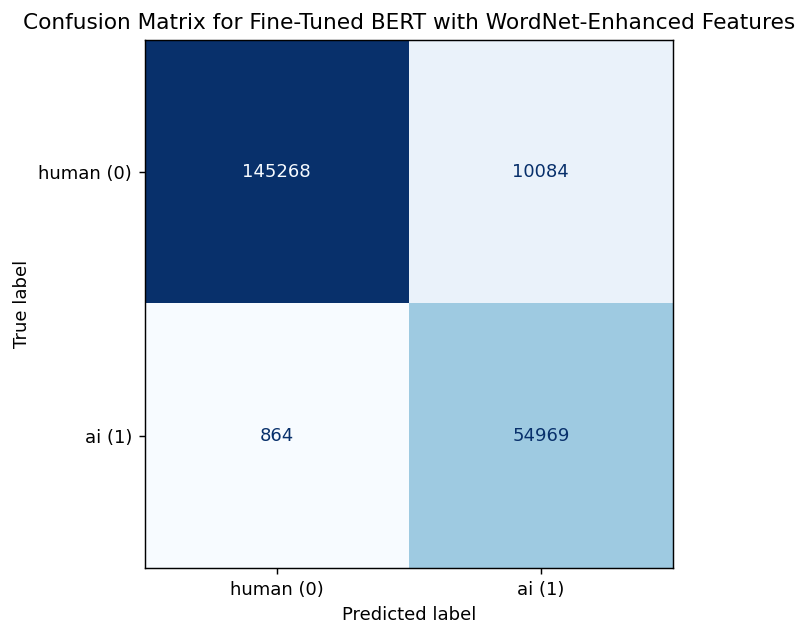

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(test_predictions['label'], test_predictions['prediction'], labels=[0, 1])
cm_df = pd.DataFrame(cm, index=['actual_human_0', 'actual_ai_1'], columns=['pred_human_0', 'pred_ai_1'])

print('Test confusion matrix')
print(cm_df.to_string())

fig, ax = plt.subplots(figsize=(6.0, 5.0))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['human (0)', 'ai (1)'])
disp.plot(cmap='Blues', values_format='d', ax=ax, colorbar=False)
ax.set_title('Confusion Matrix for Fine-Tuned BERT with WordNet-Enhanced Features')
fig.tight_layout()

### Test Metric Visualization

In addition to the confusion matrix, the following figure visualises the final **test-set** values of:

- **Accuracy**
- **Precision**
- **Recall**
- **F1-score**

This provides a compact summary of the saved final performance of Model 4 in the same report-style presentation used for the other model notebooks.

Final test metrics summary
   metric  value
 Accuracy 0.9482
Precision 0.8450
   Recall 0.9845
 F1-score 0.9094


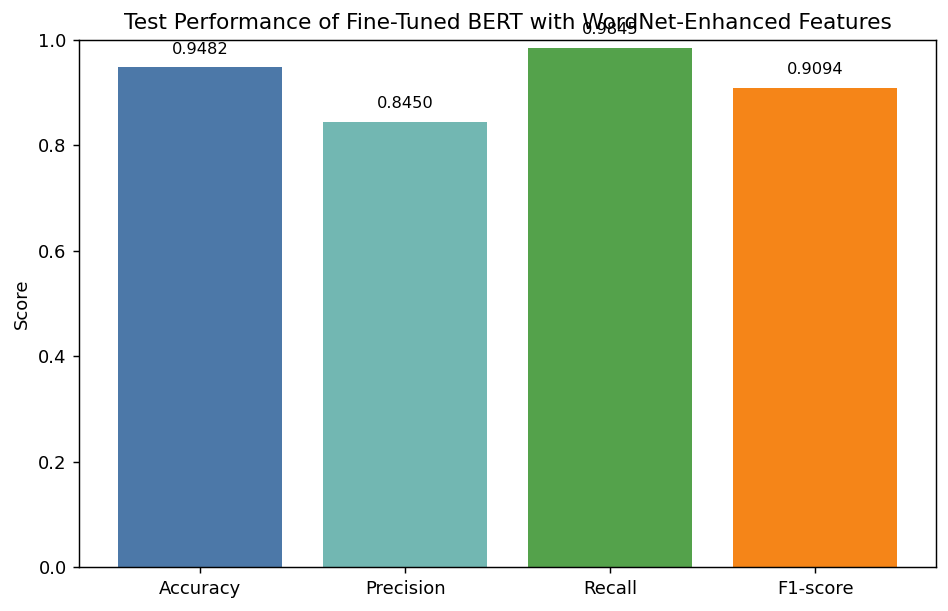

In [9]:
test_metric_df = pd.DataFrame(
    [
        {'metric': 'Accuracy', 'value': metrics['test']['accuracy']},
        {'metric': 'Precision', 'value': metrics['test']['precision']},
        {'metric': 'Recall', 'value': metrics['test']['recall']},
        {'metric': 'F1-score', 'value': metrics['test']['f1']},
    ]
)

print('Final test metrics summary')
print(test_metric_df.assign(value=test_metric_df['value'].map(lambda x: f'{float(x):.4f}')).to_string(index=False))

fig, ax = plt.subplots(figsize=(7.4, 4.8))
bars = ax.bar(
    test_metric_df['metric'],
    test_metric_df['value'],
    color=['#4C78A8', '#72B7B2', '#54A24B', '#F58518']
)
ax.set_ylim(0.0, 1.0)
ax.set_ylabel('Score')
ax.set_title('Test Performance of Fine-Tuned BERT with WordNet-Enhanced Features')
for bar, value in zip(bars, test_metric_df['value']):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f'{value:.4f}',
        ha='center',
        va='bottom',
        fontsize=9,
    )
fig.tight_layout()

### Conclusion

This notebook presents the complete final version of **Model 4: Fine-Tuned BERT with WordNet-Enhanced Features** in a single submission file. It summarises the model motivation, feature engineering method, model architecture, training pipeline, and final saved results.

Under the confirmed formal comparison setting, the model achieved strong and stable performance on both validation and test data, with a **test accuracy of 0.9482** and a **test F1-score of 0.9094** on the full official test set.

Overall, these results show that combining transformer-based contextual embeddings with WordNet-derived lexical-semantic features is an effective approach for the AI-text detection task in this project.